# 03 · Overture layers at tract level

What do the Overture buildings, roads, POIs, rail and transit layers look like inside the scored tracts? Plots use per-tract aggregates from `analysis_outputs/` (no DuckDB or raw zips needed).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "analysis_outputs").exists())
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})

REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

# one table: Overture aggregates + ACS + strata, one row per scored tract (built by the earlier notebooks)
df = pd.read_parquet(OUT / "tract_analysis_table.parquet")
df["land_km2"] = df.ALAND / 1e6

def box_by_region(ax, col, data=None, log=False, title="", ylabel=None):
    """Box plot of one column for each region (log10 if log=True), n shown under each box."""
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    """Number of values outside the 1.5 x IQR fences."""
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    """Annotated heatmap of a DataFrame."""
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Who supplied the buildings?

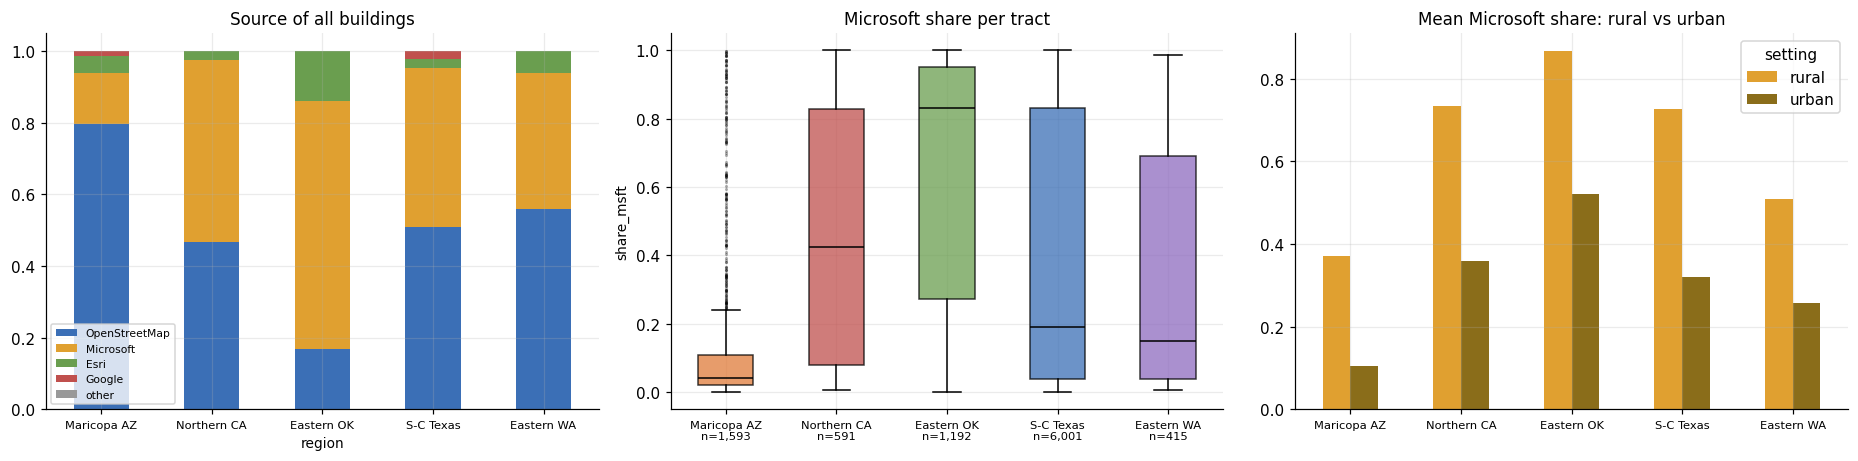

                  OpenStreetMap  Microsoft  Esri  Google  other
region                                                         
maricopa-az                0.80       0.14  0.05    0.01    0.0
northern-ca                0.47       0.51  0.03    0.00    0.0
eastern-ok                 0.17       0.69  0.14    0.00    0.0
south-central-tx           0.51       0.44  0.02    0.02    0.0
eastern-wa                 0.56       0.38  0.06    0.00    0.0


In [2]:
src = ["bldg_n_osm", "bldg_n_msft", "bldg_n_esri", "bldg_n_google", "bldg_n_other"]
mix = df.groupby("region")[src].sum().div(df.groupby("region").bldg_n.sum(), axis=0).reindex(REG); mix.columns = ["OpenStreetMap", "Microsoft", "Esri", "Google", "other"]
df["setting"] = np.where(df.rural, "rural", "urban")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
mix.plot.bar(stacked=True, ax=ax[0], rot=0, color=["#3b6fb6", "#e0a030", "#6a9e4f", "#c0504d", "#999"]); ax[0].set_title("Source of all buildings"); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].legend(fontsize=7)
box_by_region(ax[1], "share_msft", title="Microsoft share per tract")
ms = df.pivot_table(index="region", columns="setting", values="share_msft", aggfunc="mean").reindex(REG)
ms.plot.bar(ax=ax[2], rot=0, color=["#e0a030", "#8a6d1a"]); ax[2].set_title("Mean Microsoft share: rural vs urban"); ax[2].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[2].set_xlabel("")
plt.tight_layout(); plt.show(); print(mix.round(2).to_string())

**Takeaway:** Microsoft footprints are about 69% of Eastern Oklahoma buildings but only 14% in Maricopa, and in every region rural tracts rely on Microsoft far more than urban ones. The building reference used by the target is therefore already inside Overture in rural areas.

## 2. Building quality: footprint size, tiny polygons, height

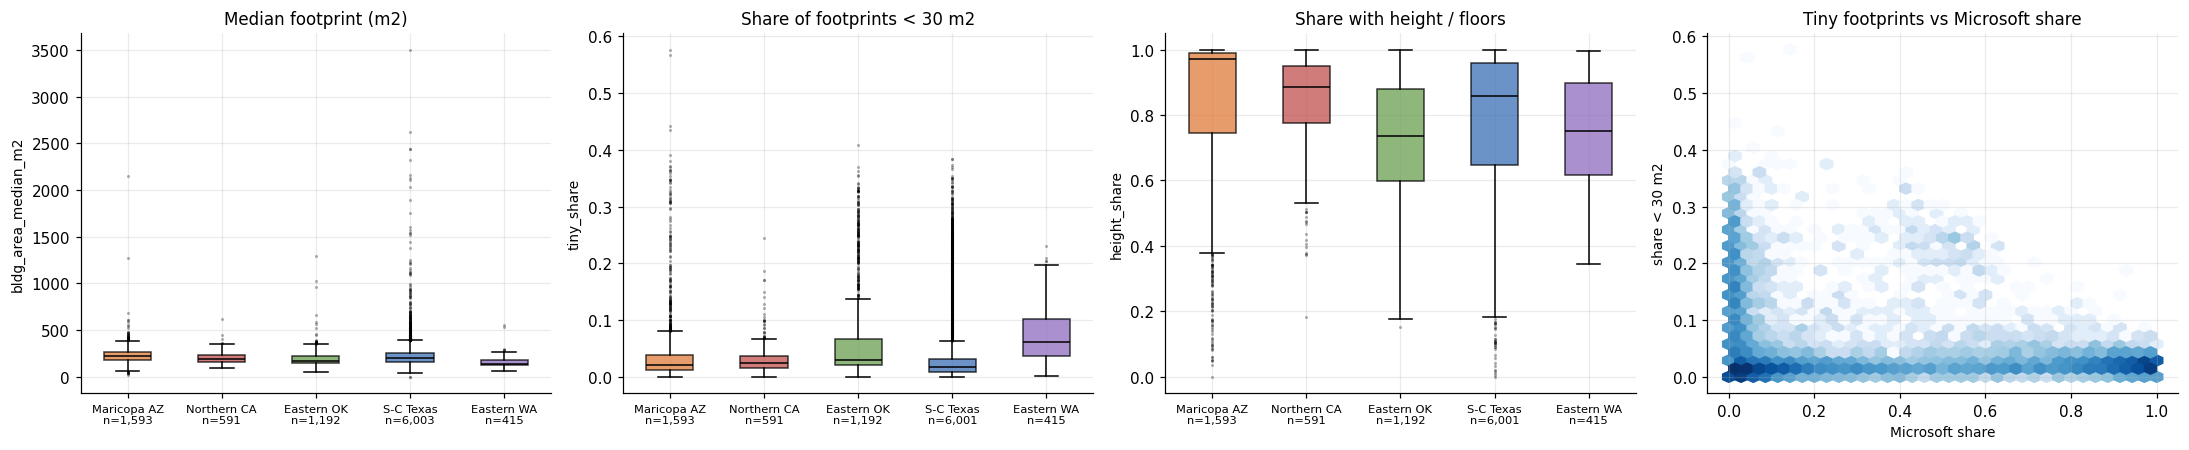

Spearman(Microsoft share, tiny share) = -0.03


In [3]:
df["tiny_share"] = df.bldg_n_lt30m2 / df.bldg_n.replace(0, np.nan); df["height_share"] = df.bldg_n_with_height / df.bldg_n.replace(0, np.nan)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
box_by_region(ax[0], "bldg_area_median_m2", title="Median footprint (m2)"); box_by_region(ax[1], "tiny_share", title="Share of footprints < 30 m2"); box_by_region(ax[2], "height_share", title="Share with height / floors")
ax[3].hexbin(df.share_msft, df.tiny_share, gridsize=35, cmap="Blues", mincnt=1, bins="log"); ax[3].set(xlabel="Microsoft share", ylabel="share < 30 m2", title="Tiny footprints vs Microsoft share")
plt.tight_layout(); plt.show(); print("Spearman(Microsoft share, tiny share) =", round(stats.spearmanr(df.share_msft, df.tiny_share, nan_policy="omit")[0], 2))

**Takeaway:** median footprints are similar (about 200 m2, a little smaller in Eastern WA). The share of tiny polygons is highest in Eastern WA, and height/floor data is nearly complete in Maricopa (median share about 97%) but much patchier in Eastern Oklahoma (about 74%). Tiny-polygon share is not related to the Microsoft share (Spearman -0.03), so these differences come from elsewhere.

## 3. Roads: class mix and density

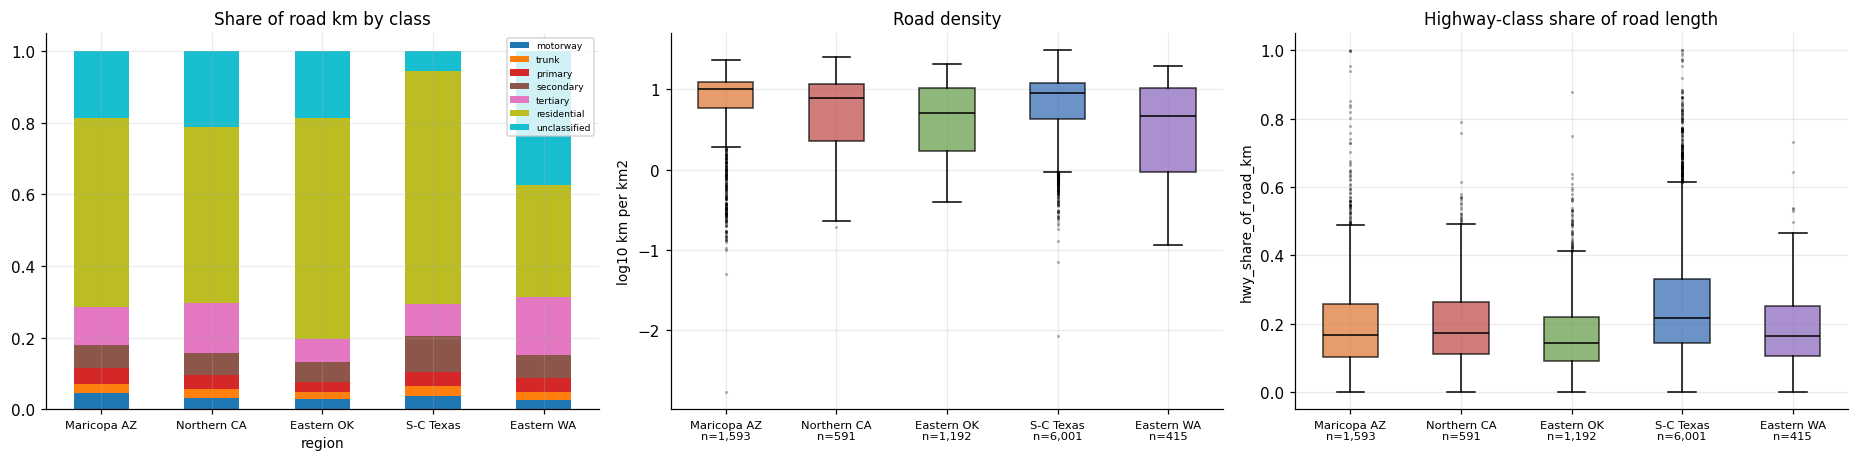

region
maricopa-az         124.0
northern-ca          77.0
eastern-ok          213.0
south-central-tx    576.0
eastern-wa           79.0


In [4]:
cls = ["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "unclassified"]
rk = df.groupby("region")[[f"road_km_{c}" for c in cls]].sum().reindex(REG); rk.columns = cls
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
rk.div(rk.sum(axis=1), axis=0).plot.bar(stacked=True, ax=ax[0], rot=0, colormap="tab10"); ax[0].set_title("Share of road km by class"); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].legend(fontsize=6)
box_by_region(ax[1], "road_km_per_km2", log=True, title="Road density", ylabel="log10 km per km2"); box_by_region(ax[2], "hwy_share_of_road_km", title="Highway-class share of road length")
plt.tight_layout(); plt.show(); print((rk.sum(axis=1) / 1e3).round(0).rename("road km (thousands)").to_string())

**Takeaway:** residential streets dominate everywhere and the four highway classes the target uses are only about 13-20% of road length. Road density spans about three orders of magnitude across tracts.

## 4. Points of interest per tract

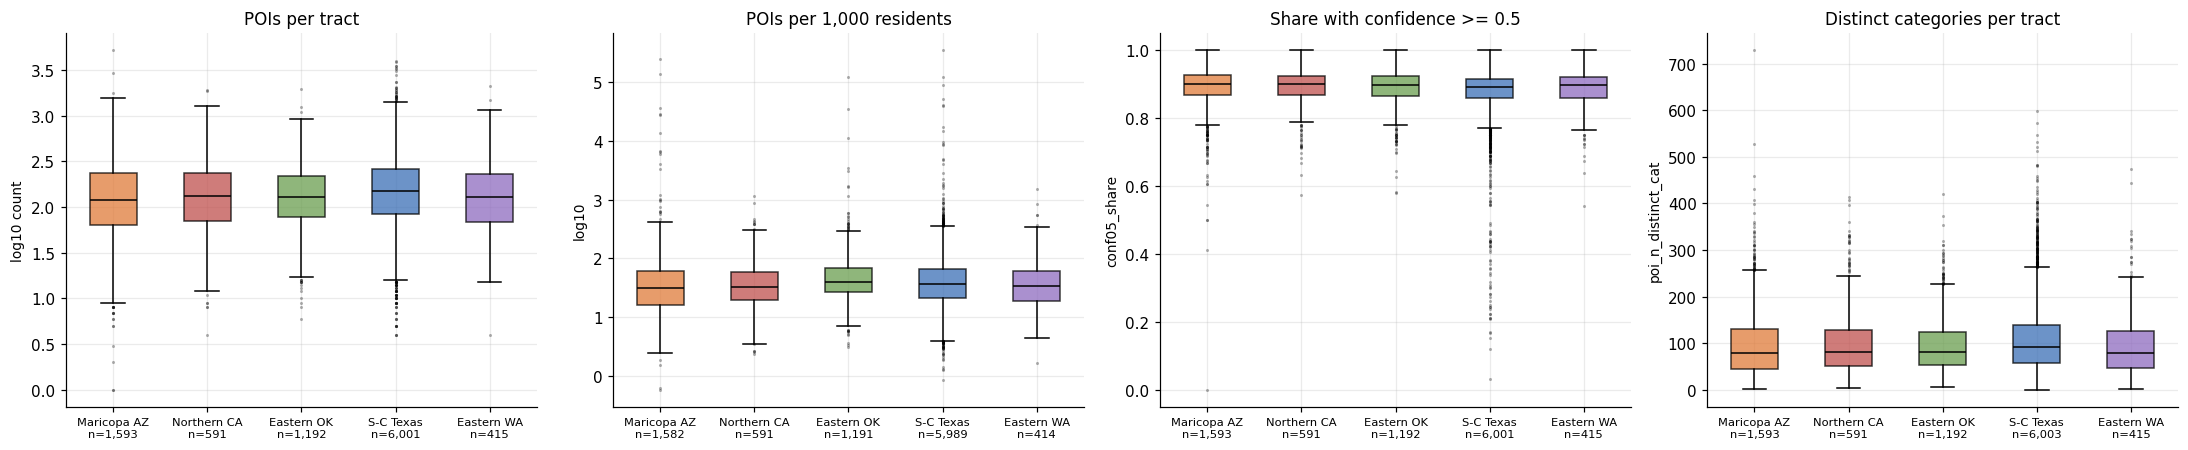

tracts with zero POIs: 2 | median POIs per tract: {'maricopa-az': 120, 'northern-ca': 134, 'eastern-ok': 128, 'south-central-tx': 151, 'eastern-wa': 129}


In [5]:
df["conf05_share"] = df.poi_n_conf05 / df.poi_n.replace(0, np.nan)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
box_by_region(ax[0], "poi_n", log=True, title="POIs per tract", ylabel="log10 count"); box_by_region(ax[1], "poi_per_1k_pop", log=True, title="POIs per 1,000 residents", ylabel="log10"); box_by_region(ax[2], "conf05_share", title="Share with confidence >= 0.5"); box_by_region(ax[3], "poi_n_distinct_cat", title="Distinct categories per tract")
plt.tight_layout(); plt.show(); print("tracts with zero POIs:", int((df.poi_n == 0).sum()), "| median POIs per tract:", df.groupby("region").poi_n.median().reindex(REG).astype(int).to_dict())

**Takeaway:** the median tract has roughly 120-150 POIs but counts reach over 5,000, so a log scale is essential. POIs per resident are similar across regions, so differences in raw counts mostly reflect population.

## 5. The facility types the target uses: fire, EMS, schools, hospitals

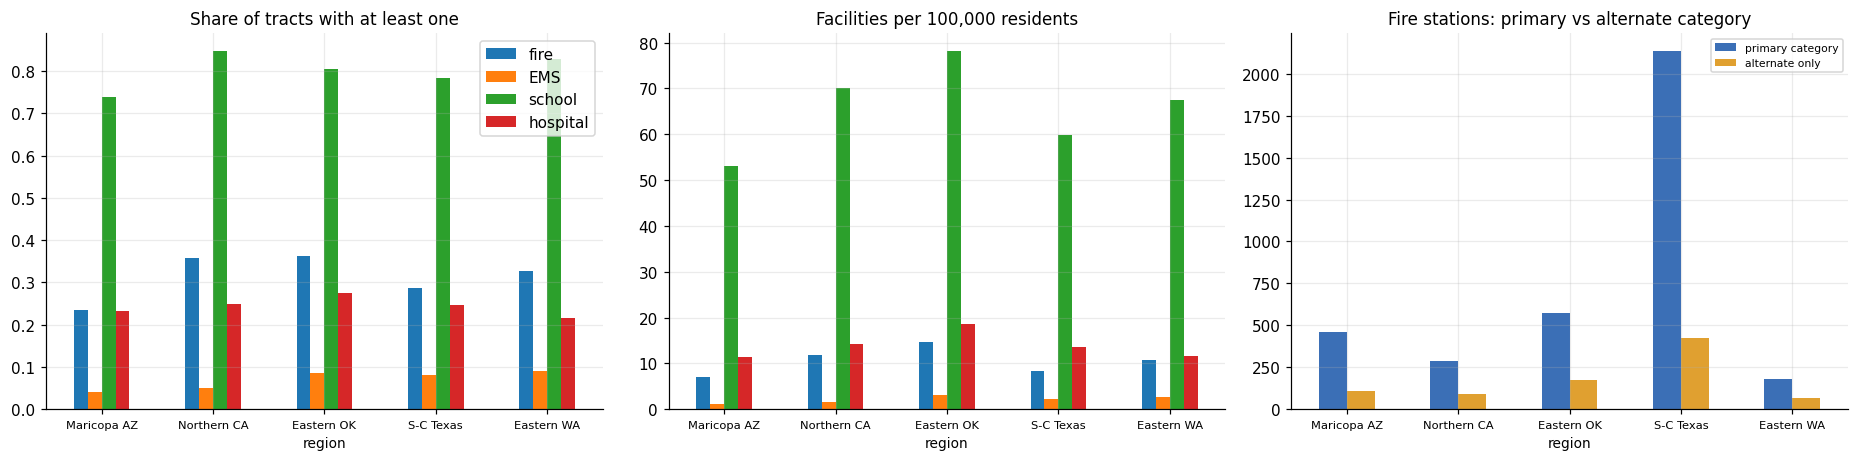

                  fire  EMS  school  hospital
region                                       
maricopa-az       23.4  4.1    73.9      23.2
northern-ca       35.9  5.1    84.8      24.9
eastern-ok        36.2  8.6    80.5      27.5
south-central-tx  28.8  8.0    78.5      24.6
eastern-wa        32.8  9.2    82.9      21.7
                  fire  EMS  school  hospital
region                                       
maricopa-az        7.0  1.1    53.0      11.5
northern-ca       11.8  1.5    70.1      14.2
eastern-ok        14.7  3.1    78.2      18.7
south-central-tx   8.3  2.2    59.9      13.7
eastern-wa        10.7  2.6    67.4      11.7


In [6]:
fac = {"fire": "poi_n_fire", "EMS": "poi_n_ems", "school": "poi_n_school", "hospital": "poi_n_hospital"}
pres = pd.DataFrame({k: df.groupby("region")[c].apply(lambda s: (s > 0).mean()) for k, c in fac.items()}).reindex(REG)
per = df.groupby("region")[list(fac.values())].sum().reindex(REG).div(df.groupby("region").pop_total.sum().reindex(REG), axis=0) * 1e5; per.columns = fac.keys()
alt = df.groupby("region")[["poi_n_fire", "poi_n_fire_alt"]].sum().reindex(REG)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
pres.plot.bar(ax=ax[0], rot=0); ax[0].set_title("Share of tracts with at least one"); per.plot.bar(ax=ax[1], rot=0, legend=False); ax[1].set_title("Facilities per 100,000 residents")
alt.plot.bar(ax=ax[2], rot=0, color=["#3b6fb6", "#e0a030"]); ax[2].set_title("Fire stations: primary vs alternate category"); ax[2].legend(["primary category", "alternate only"], fontsize=7)
for a in ax: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5)
plt.tight_layout(); plt.show(); print((pres * 100).round(1).to_string()); print(per.round(1).to_string())

**Takeaway:** a fire-department POI exists in only 23-36% of tracts and an EMS POI in 4-9%, so facility gaps are lumpy. Maricopa has the fewest fire stations per resident. The target counts only the primary category, yet a sizeable number of fire stations are listed only as an alternate category.

## 6. Rail and transit

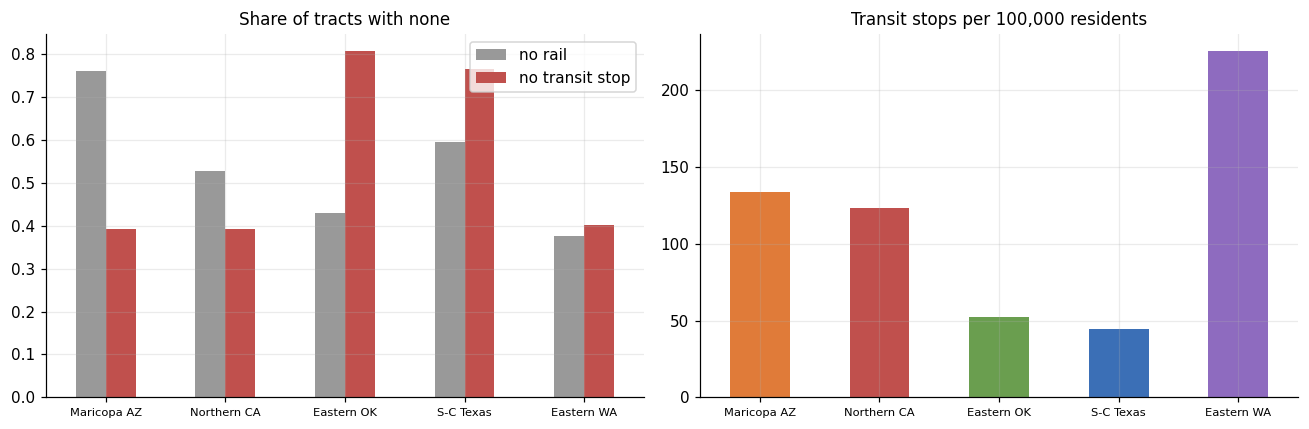

                  no rail  no transit stop
region                                    
maricopa-az          76.0             39.0
northern-ca          53.0             39.0
eastern-ok           43.0             81.0
south-central-tx     60.0             76.0
eastern-wa           38.0             40.0


In [7]:
none = pd.DataFrame({"no rail": df.groupby("region").rail_km.apply(lambda s: (s == 0).mean()), "no transit stop": df.groupby("region").infra_n_transit.apply(lambda s: (s == 0).mean())}).reindex(REG)
stops = df.groupby("region").infra_n_transit.sum().reindex(REG) / df.groupby("region").pop_total.sum().reindex(REG) * 1e5
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
none.plot.bar(ax=ax[0], rot=0, color=["#999", "#c0504d"]); ax[0].set_title("Share of tracts with none"); stops.plot.bar(ax=ax[1], rot=0, color=[COL[r] for r in REG]); ax[1].set_title("Transit stops per 100,000 residents")
for a in ax: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5); a.set_xlabel("")
plt.tight_layout(); plt.show(); print((none * 100).round(0).to_string())

**Takeaway:** about 80% of Oklahoma and Texas tracts have no transit stop, versus roughly 40% elsewhere. Overture alone cannot say whether that is real scarcity or a mapping gap.

## 7. How do the layers relate, and where are the outliers?

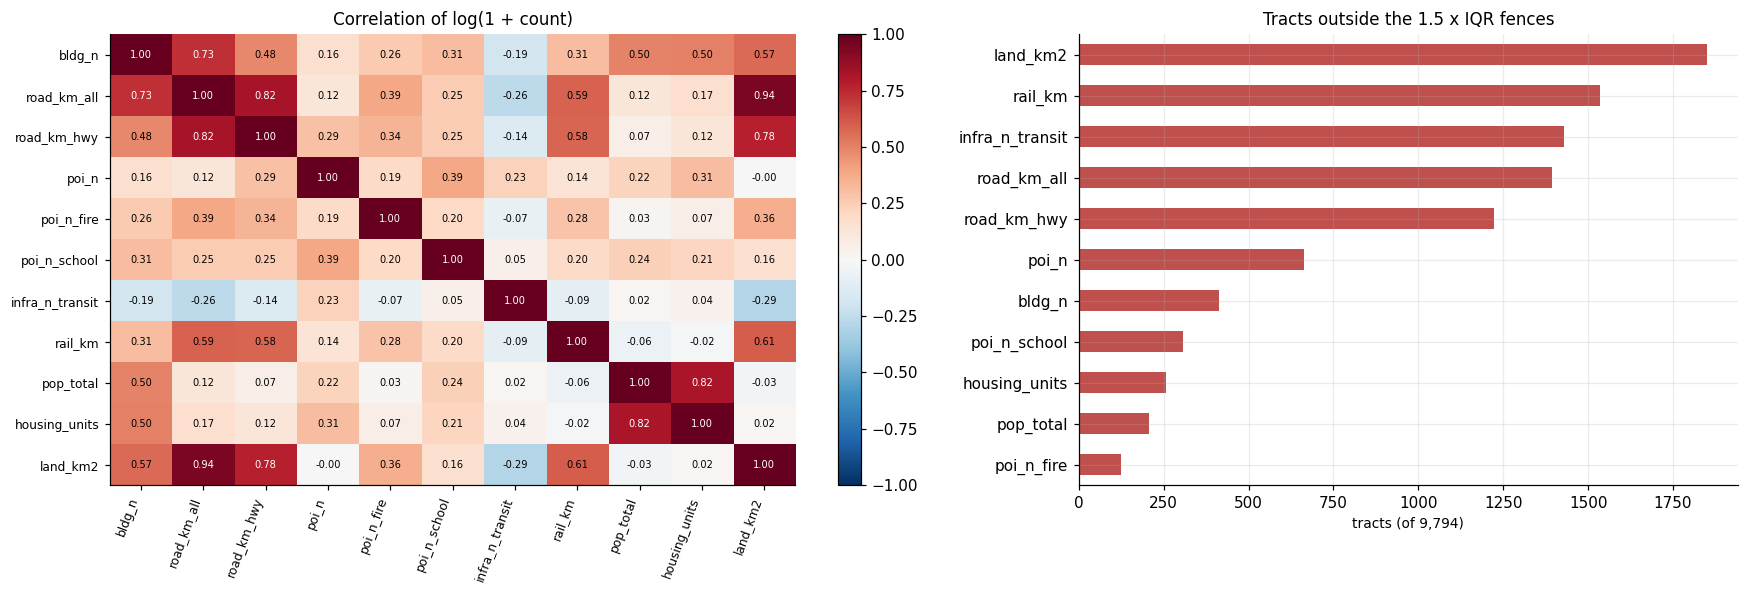

In [8]:
c = ["bldg_n", "road_km_all", "road_km_hwy", "poi_n", "poi_n_fire", "poi_n_school", "infra_n_transit", "rail_km", "pop_total", "housing_units", "land_km2"]
cm = np.log1p(df[c].clip(lower=0)).corr()
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
plt.colorbar(heat(ax[0], cm, fs=6.5, rot=70), ax=ax[0]); ax[0].set_title("Correlation of log(1 + count)")
pd.Series({k: n_outliers(df[k]) for k in c}).sort_values().plot.barh(ax=ax[1], color="#c0504d"); ax[1].set_title("Tracts outside the 1.5 x IQR fences"); ax[1].set_xlabel("tracts (of 9,794)")
plt.tight_layout(); plt.show()

**Takeaway:** road length tracks land area (r = 0.9) and buildings (0.7), and population tracks housing units (0.8), but POI counts are only weakly related to anything (r from 0.0 to 0.4). Raw counts have many outliers (up to about 1,850 tracts for area), so ratios or logs are needed.